In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

In [73]:
df1 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1.csv')
df2 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-2.csv')
df3 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-3.csv')
df5 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-5.csv')
df4 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-4.tsv', sep='\t')
df6 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-6.csv')
df7 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-7.tsv', sep='\t')
df8 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-8.csv')
df9 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-9.csv')
df10 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-10.csv')
df11 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-11.csv')
df12 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-12.csv')
df13 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-13.csv')
df14 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-14.csv')
df15 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-15.csv')
df16 = pd.read_csv('/Users/thachdang/Documents/TIM/UHMWPE Testing/segment1-16.csv')

In [74]:
# Remove leading and trailing spaces from column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()
df3.columns = df3.columns.str.strip()
df4.columns = df4.columns.str.strip()
df5.columns = df5.columns.str.strip()
df6.columns = df6.columns.str.strip()
df7.columns = df7.columns.str.strip()
df8.columns = df8.columns.str.strip()
df9.columns = df9.columns.str.strip()
df10.columns = df10.columns.str.strip()
df11.columns = df11.columns.str.strip()
df12.columns = df12.columns.str.strip()
df13.columns = df13.columns.str.strip()
df14.columns = df14.columns.str.strip()
df15.columns = df15.columns.str.strip()
df16.columns = df16.columns.str.strip()

In [76]:
df5.head(-1)

,CycleCount,Position,Time,_Load,_Strain1,_Strain2,Stress,Strain1,Strain2
0,CycleCount,mm,sec,kN,mm,mm,MPa,mm/mm,mm/mm
1,1,0,0.342000007629395,-0.000711638748645783,1.00541568826884,0.0410213506256696,44.7058833502,-2.80172735687e-05,1.00541568827
2,1,-0.000101725262879881,0.351999998092651,-0.000709738314151764,1.00569927599281,0.0410260654462036,46.0130716461,-2.79424533131e-05,1.00569927599
3,1,-0.0021870930595469,0.361999988555908,-0.000732690036296844,1.00611336529255,0.0410085121984594,47.3202599419,-2.88460644211e-05,1.00611336529
4,1,-0.0133768717205385,0.372000008821487,-0.00108880019187927,1.00598949939013,0.0410134889534675,48.6274521335,-4.28661492866e-05,1.00598949939
...,...,...,...,...,...,...,...,...,...
3996,1,-0.000356038412974158,40.2919998168945,-0.000240488961338997,1.01465382613242,0.0410397005907726,5266.92808064,-9.46806934406e-06,1.01465382613
3997,1,-0.000356038412974158,40.3019981384277,-0.000246336907148361,1.01459003053606,0.0410129359806888,5268.23505077,-9.69830343104e-06,1.01459003054
3998,1,-0.000356038412974158,40.3120002746582,-0.00024784716963768,1.0146388085559,0.0410381690016948,5269.54251956,-9.75776258416e-06,1.01463880856
3999,1,-0.000356038412974158,40.3219985961914,-0.000243422582745552,1.01464008912444,0.0410475404351018,5270.8494897,-9.58356624982e-06,1.01464008912


In [79]:
# Trim spaces from column names
df4.columns = df4.columns.str.strip()

# Remove any non-numeric characters (e.g., commas, spaces) and convert to numeric
df4["_Load"] = pd.to_numeric(df4["_Load"].astype(str).str.replace(r"[^\d.-]", "", regex=True), errors="coerce")
df4["_Strain1"] = pd.to_numeric(df4["_Strain1"].astype(str).str.replace(r"[^\d.-]", "", regex=True), errors="coerce")

# Add the calculated columns
df4["Stress"] = df4["_Load"]*1000 / (7.654)
df4["Strain"] = df4["_Strain1"] / 25.4

# Display the first few rows
df4.head(-1)

,CycleCount,Position,_Load,_Strain1,_Strain2,Crosshead Segment Integer Count,Running Time,Rollover Running Time,Stress,Strain
0,CycleCount,mm,NaN,NaN,mm,cycles,sec,sec,NaN,NaN
1,1,0.0224812829401344,0.009176,0.005673,0.0386989195249043,0,0.416000008583069,0.416000008583069,1.198912,0.000223
2,1,0.0754801440052688,0.011631,0.027709,0.0386998362955637,0,0.465999990701675,0.465999990701675,1.519564,0.001091
3,1,0.12858072295785,0.015524,0.050948,0.0387185718864202,0,0.515999972820282,0.515999972820282,2.028254,0.002006
4,1,0.180206305230968,0.019698,0.072899,0.0386998362955637,0,0.565999984741211,0.565999984741211,2.573617,0.002870
...,...,...,...,...,...,...,...,...,...,...
4795,1,239.744827151299,0.291483,-0.012374,0.0387618165405001,0,240.115997314453,240.115997314453,38.082453,-0.000487
4796,1,239.794358611107,0.291445,-0.012299,0.0387763830076437,0,240.166000366211,240.166000366211,38.077517,-0.000484
4797,1,239.844098687172,0.291519,-0.012417,0.0387656873499509,0,240.216003417969,240.216003417969,38.087082,-0.000489
4798,1,239.894762635231,0.291585,-0.012418,0.0387498002965003,0,240.266006469727,240.266006469727,38.095778,-0.000489


In [81]:
df7.columns = df7.columns.str.strip()

df7["_Load"] = pd.to_numeric(df7["_Load"].astype(str).str.replace(r"[^\d.-]", "", regex=True), errors="coerce")
df7["_Strain1"] = pd.to_numeric(df7["_Strain1"].astype(str).str.replace(r"[^\d.-]", "", regex=True), errors="coerce")

df7["Stress"] = df7["_Load"] / (12.17e-3)
df7["Strain"] = df7["_Strain1"] / 25.4

# Display the first few rows
df7.head()

,CycleCount,Position,_Load,_Strain1,_Strain2,Crosshead Segment Integer Count,Running Time,Rollover Running Time,Stress,Strain
0,CycleCount,mm,NaN,NaN,mm,cycles,sec,sec,NaN,NaN
1,1,0.0189208985830192,0.009629,0.000583,0.0387107174901757,0,0.409999996423721,0.409999996423721,0.791222,0.000023
2,1,0.0721232063369825,0.015052,0.019289,0.0387359941669274,0,0.46000000834465,0.46000000834465,1.236846,0.000759
3,1,0.124766025692225,0.021923,0.038573,0.0387307263736147,0,0.509999990463257,0.509999990463257,1.801405,0.001519
4,1,0.176442466909066,0.028902,0.057934,0.0387344516639132,0,0.560000002384186,0.560000002384186,2.374863,0.002281


In [83]:
df1 = df1.iloc[1:].copy()
df1 = df1.apply(pd.to_numeric, errors='coerce')

df2 = df2.iloc[1:].copy()
df2 = df2.apply(pd.to_numeric, errors='coerce')

df3 = df3.iloc[1:].copy()
df3 = df3.apply(pd.to_numeric, errors='coerce')

df4 = df4.iloc[1:].copy()
df4 = df4.apply(pd.to_numeric, errors='coerce')

df5 = df5.iloc[1:].copy()
df5 = df5.apply(pd.to_numeric, errors='coerce')

df6 = df6.iloc[1:].copy()
df6 = df6.apply(pd.to_numeric, errors='coerce')

df7 = df7.iloc[1:].copy()
df7 = df7.apply(pd.to_numeric, errors='coerce')

df8 = df8.iloc[1:].copy()
df8 = df8.apply(pd.to_numeric, errors='coerce')

df9 = df9.iloc[1:].copy()
df9 = df9.apply(pd.to_numeric, errors='coerce')

df10 = df10.iloc[1:].copy()
df10 = df10.apply(pd.to_numeric, errors='coerce')

df11 = df11.iloc[1:].copy()
df11 = df11.apply(pd.to_numeric, errors='coerce')

df12 = df12.iloc[1:].copy()
df12 = df12.apply(pd.to_numeric, errors='coerce')

df13 = df13.iloc[1:].copy()
df13 = df13.apply(pd.to_numeric, errors='coerce')

df14 = df14.iloc[1:].copy()
df14 = df14.apply(pd.to_numeric, errors='coerce')

df15 = df15.iloc[1:].copy()
df15 = df15.apply(pd.to_numeric, errors='coerce')

df16 = df16.iloc[1:].copy()
df16 = df16.apply(pd.to_numeric, errors='coerce')

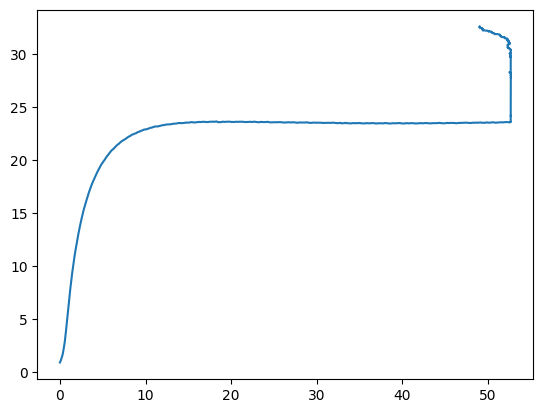

In [84]:
plt.plot(df15["Strain1"]*100,df15["Stress"])
plt.show()

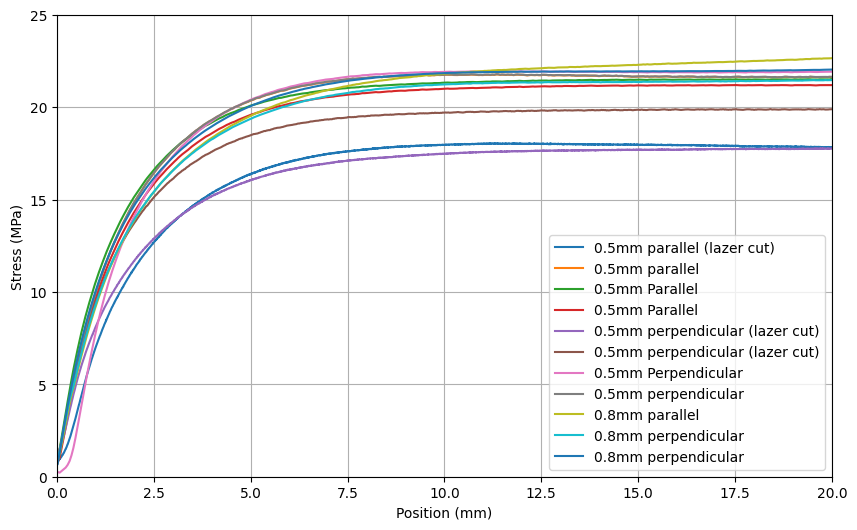

In [87]:
plt.figure(figsize=(10, 6))

plt.plot(df1["Position"][:4901],df1["Stress"][:4901], markersize=1, label = '0.5mm parallel (lazer cut)')
plt.plot(df4["Position"][:1050], df4["Stress"][:1050], markersize=1, label = '0.5mm parallel')
#plt.plot(df5["Position"][:3499],df5["Stress"][:3499], markersize=1, label = '0.5mm parallel')
plt.plot(df12["Position"][:1770], df12["Stress"][:1770], markersize=1, label = '0.5mm Parallel')
plt.plot(df13["Position"][:989], df13["Stress"][:989], markersize=1, label = '0.5mm Parallel')
plt.plot(df2["Position"][:4733],df2["Stress"][:4733], markersize=1, label = '0.5mm perpendicular (lazer cut)')
plt.plot(df3["Position"][:1402],df3["Stress"][:1402], markersize=1, label = '0.5mm perpendicular (lazer cut)')
plt.plot(df10["Position"][:994], df10["Stress"][:994], label = '0.5mm Perpendicular')
plt.plot(df6["Position"][:1051],df6["Stress"][:1051], markersize=1, label = '0.5mm perpendicular')
plt.plot(df7["Position"][:1710], df7["Stress"][:1710], markersize=1, label = '0.8mm parallel') #Weird ass data
plt.plot(df8["Position"][:581],df8["Stress"][:581], markersize=1, label = '0.8mm perpendicular')
plt.plot(df9["Position"][:1743], df9["Stress"][:1743], label = '0.8mm perpendicular')
#plt.plot(df11["Position"][:816], df11["Stress"][:816], markersize=1, label = '0.5mm Perpendicular')
#plt.plot(df15["Position"][:1280], df15["Stress"][:1280], markersize=1, label = '0.25mm Parallel') 
#plt.plot(df14["Position"][:1995], df14["Stress"][:1995], markersize=1, label = '0.25mm Perpendicular') 
#plt.plot(df16["Position"][:8331], df16["Stress"][:8331], markersize=1, label = '0.25mm Perpendicular') 

plt.xlim(0,20)
plt.ylim(0,25)

plt.ylabel("Stress (MPa)")
plt.xlabel("Position (mm)")
plt.legend()
plt.grid()

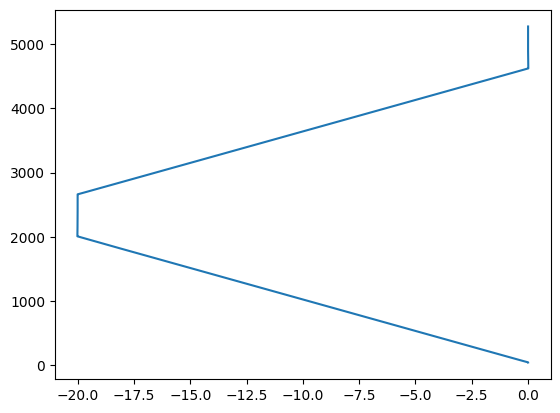

In [88]:
plt.plot(df5["Position"],df5["Stress"], markersize=1, label = '0.5mm parallel')


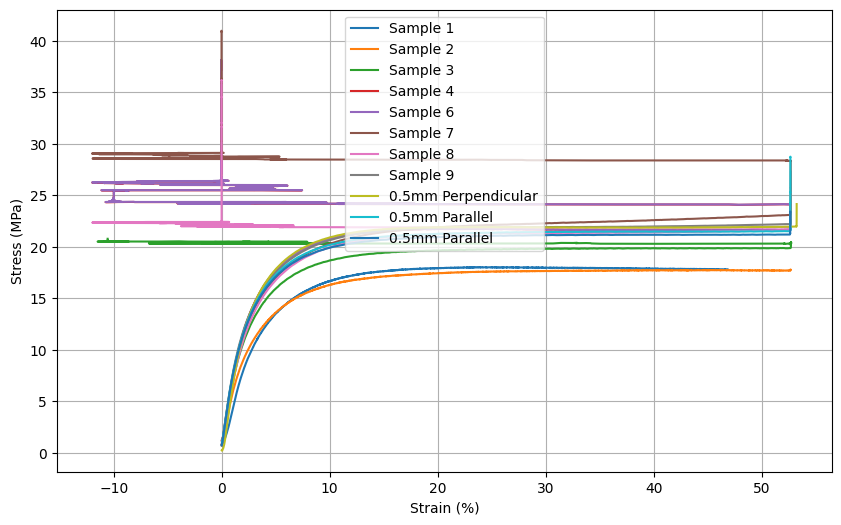

In [91]:
plt.figure(figsize=(10, 6))

plt.plot(df1["Strain1"]*100, df1["Stress"], label = 'Sample 1')
plt.plot(df2["Strain1"]*100, df2["Stress"], label = 'Sample 2')
plt.plot(df3["Strain1"]*100, df3["Stress"], markersize=1, label = 'Sample 3')
plt.plot(df4["Strain"]*100, df4["Stress"], markersize=1, label = 'Sample 4')
#plt.plot(df5["Strain1"]*100, df5["Stress"], markersize=1, label = 'Sample 5') #Weird ass data
plt.plot(df6["Strain1"]*100, df6["Stress"], markersize=1, label = 'Sample 6')
plt.plot(df7["Strain"]*100, df7["Stress"], markersize=1, label = 'Sample 7') 
plt.plot(df8["Strain1"]*100, df8["Stress"], markersize=1, label = 'Sample 8') 
plt.plot(df9["Strain1"]*100, df9["Stress"], label = 'Sample 9')
plt.plot(df10["Strain1"]*100, df10["Stress"], label = '0.5mm Perpendicular')
#plt.plot(df11["Strain1"]*100, df11["Stress"], markersize=1, label = '0.5mm Perpendicular')
plt.plot(df12["Strain1"]*100, df12["Stress"], markersize=1, label = '0.5mm Parallel')
plt.plot(df13["Strain1"]*100, df13["Stress"], markersize=1, label = '0.5mm Parallel')
#plt.plot(df14["Strain1"]*100, df14["Stress"], markersize=1, label = '0.25mm Perpendicular') 
#plt.plot(df15["Strain1"]*100, df15["Stress"], markersize=1, label = '0.25mm Parallel') 
#plt.plot(df16["Strain1"]*100, df16["Stress"], markersize=1, label = '0.25mm Perpendicular') 


plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.legend()
plt.grid()

In [92]:
print(np.where(df1['Strain1'] == np.max(df1['Strain1'])))
print(np.where(df2['Strain1'] == np.max(df2['Strain1'])))
print(np.where(df3['Strain1'] == np.max(df3['Strain1'])))
print(np.where(df4['Strain'] == np.max(df4['Strain'])))
print(np.where(df5['Strain1'] == np.max(df5['Strain1'])))
print(np.where(df6['Strain1'] == np.max(df6['Strain1'])))
print(np.where(df7['Strain'] == np.max(df7['Strain'])))
print(np.where(df8['Strain1'] == np.max(df8['Strain1'])))
print(np.where(df9['Strain1'] == np.max(df9['Strain1'])))
print(np.where(df10['Strain1'] == np.max(df10['Strain1'])))
print(np.where(df11['Strain1'] == np.max(df11['Strain1'])))
print(np.where(df12['Strain1'] == np.max(df12['Strain1'])))
print(np.where(df13['Strain1'] == np.max(df13['Strain1'])))
print(np.where(df14['Strain1'] == np.max(df14['Strain1'])))
print(np.where(df15['Strain1'] == np.max(df15['Strain1'])))
print(np.where(df16['Strain1'] == np.max(df16['Strain1'])))

(array([3999]),)
(array([4719]),)
(array([1402]),)
(array([1052]),)
(array([3500]),)
(array([1052]),)
(array([1712]),)
(array([581]),)
(array([1744]),)
(array([995]),)
(array([817]),)
(array([1771]),)
(array([990]),)
(array([1996]),)
(array([1281]),)
(array([8332]),)


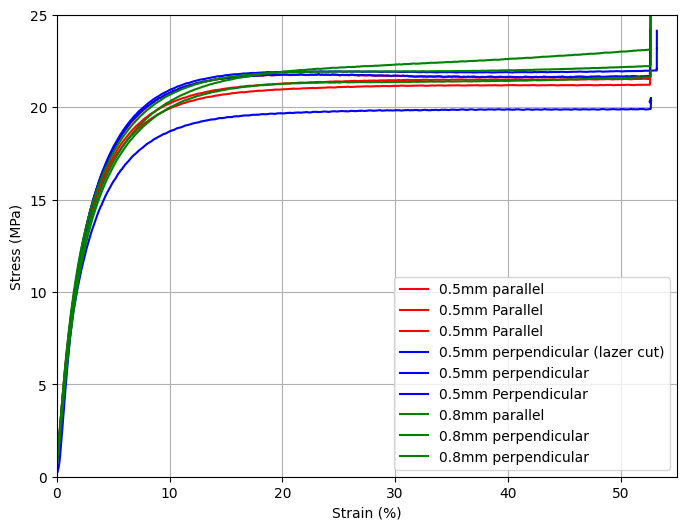

In [151]:
plt.figure(figsize=(8, 6))
# #--- 0.5 mm parallel ---
#plt.plot(df1["Strain1"][:4901]*100, df1["Stress"][:4901], markersize=1, label = '0.5mm parallel (lazer cut)')
plt.plot(df4["Strain"][:1052]*100, df4["Stress"][:1052], markersize=1, label = '0.5mm parallel', color = 'r')
#plt.plot(df5["Strain1"][:3499]*100, df5["Stress"][:3499], markersize=1, label = '0.5mm parallel')
plt.plot(df12["Strain1"][:1770]*100, df12["Stress"][:1770], markersize=1, label = '0.5mm Parallel', color = 'r')
plt.plot(df13["Strain1"][:989]*100, df13["Stress"][:989], markersize=1, label = '0.5mm Parallel', color = 'r')

# #--- 0.5 mm perpendiculaar ---
#plt.plot(df2["Strain1"][:4733]*100, df2["Stress"][:4733], markersize=1, label = '0.5mm perpendicular (lazer cut)')
plt.plot(df3["Strain1"][:1402]*100, df3["Stress"][:1402], label = '0.5mm perpendicular (lazer cut)', color = 'b')
plt.plot(df6["Strain1"][:1052]*100, df6["Stress"][:1052], label = '0.5mm perpendicular', color = 'b')
plt.plot(df10["Strain1"][:994]*100, df10["Stress"][:994], label = '0.5mm Perpendicular', color = 'b')

#--- 0.8 mm ---
plt.plot(df7["Strain"][:1712]*100, df7["Stress"][:1712], label = '0.8mm parallel', color = 'g') #Weird ass data
plt.plot(df8["Strain1"][:581]*100, df8["Stress"][:581],  label = '0.8mm perpendicular', color = 'g') 
plt.plot(df9["Strain1"][:1743]*100, df9["Stress"][:1743], label = '0.8mm perpendicular', color = 'g')
#plt.plot(df11["Strain1"][:816]*100, df11["Stress"][:816], markersize=1, label = '0.5mm Perpendicular')
#plt.plot(df15["Strain1"][:1280]*100, df15["Stress"][:1280], markersize=1, label = '0.25mm Parallel') 

# plt.plot(df14["Strain1"][:1995]*100, df14["Stress"][:1995], markersize=1, label = '0.25mm Perpendicular') 
# plt.plot(df16["Strain1"][:8331]*100, df16["Stress"][:8331], markersize=1, label = '0.25mm Perpendicular') 

plt.xlim(0,55)
plt.ylim(0,25)
plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.legend()
plt.grid()

629.0159945992415


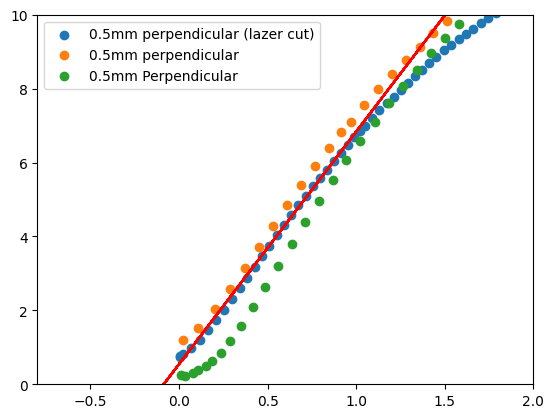

In [97]:
#0.5 mm perpendicular
slope, intercept, r_value, p_value, std_err = linregress(df3["Strain1"][:20], df3["Stress"][:20])
yfit = slope*df3["Strain1"]+intercept

plt.plot(df3["Strain1"]*100, yfit, color = 'r')
plt.scatter(df3["Strain1"][:1402]*100, df3["Stress"][:1402], label = '0.5mm perpendicular (lazer cut)')
plt.scatter(df6["Strain1"][:1052]*100, df6["Stress"][:1052], label = '0.5mm perpendicular')
plt.scatter(df10["Strain1"][:994]*100, df10["Stress"][:994], label = '0.5mm Perpendicular')

plt.ylim(0,10)
plt.xlim(-0.8,2)
print(slope)
plt.legend()


623.8352791128511


(-0.8, 10.0)

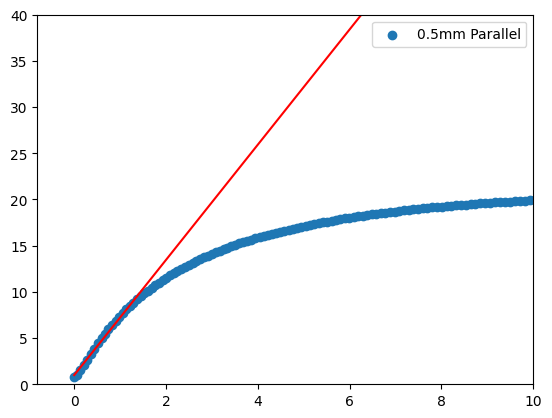

In [99]:
#0.5 mm parallel
slope, intercept, r_value, p_value, std_err = linregress(df13["Strain1"][:20], df13["Stress"][:20])
yfit = slope*df13["Strain1"]+intercept

plt.plot(df13["Strain1"]*100, yfit, color = 'r')
# plt.scatter(df4["Strain"][:1052]*100, df4["Stress"][:1052], label = '0.5mm parallel')
# plt.scatter(df12["Strain1"][:1770]*100, df12["Stress"][:1770], label = '0.5mm Parallel')
plt.scatter(df13["Strain1"][:989]*100, df13["Stress"][:989],  label = '0.5mm Parallel')
print(slope)
plt.legend()
plt.ylim(0,40)
plt.xlim(-0.8,10)

603.5968645596118


(0.0, 50.0)

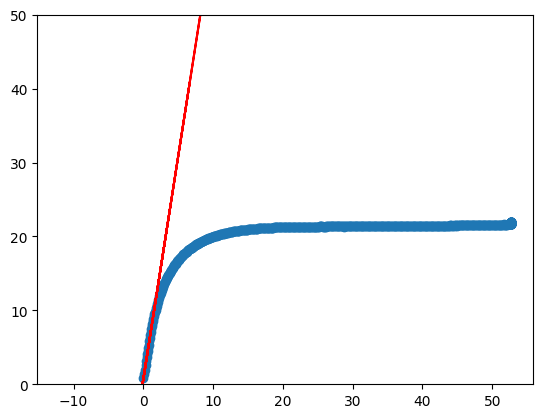

In [175]:
#0.8 mm
slope, intercept, r_value, p_value, std_err = linregress(df8["Strain1"][:12], df8["Stress"][:12])
yfit = slope*df8["Strain1"]+intercept

plt.plot(df8["Strain1"]*100, yfit, color = 'r')
# plt.scatter(df7["Strain"][:1712]*100, df7["Stress"][:1712], label = '0.8mm parallel') #Weird ass data
plt.scatter(df8["Strain1"][:581]*100, df8["Stress"][:581],  label = '0.8mm perpendicular') 
#plt.plot(df9["Strain1"][:1743]*100, df9["Stress"][:1743], label = '0.8mm perpendicular')
print(slope)
plt.ylim(0,50)

In [265]:
def get_modulus10(strain, stress, label):
    slope, intercept, r_value, p_value, std_err = linregress(strain[:10], stress[:10])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope

def get_modulus20(strain, stress, label):
    slope, intercept, r_value, p_value, std_err = linregress(strain[:20], stress[:20])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope
    
def get_modulus15(strain, stress, label):
    slope, intercept, r_value, p_value, std_err = linregress(strain[:15], stress[:15])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope

def get_modulus1perc(strain, stress, label):
    n = int(len(strain)*0.01) 
    slope, intercept, r_value, p_value, std_err = linregress(strain[:n], stress[:n])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope

def get_modulus(strain, stress, label):
    n = 16
    slope, intercept, r_value, p_value, std_err = linregress(strain[0:n], stress[0:n])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope

def get_modulus5(strain, stress, label):
    slope, intercept, r_value, p_value, std_err = linregress(strain[:5], stress[:5])
    print(f"{label}: Young's modulus = {slope:.2f} MPa")
    return slope
    
# Parallel 0.5mm
#get_modulus(df1["Strain1"], df1["Stress"], "df1 (0.5mm parallel, laser cut)")
get_modulus10(df4["Strain"], df4["Stress"], "df4 (0.5mm parallel)")
#get_modulus(df5["Strain1"], df5["Stress"], "df5 (0.5mm parallel)")
get_modulus10(df12["Strain1"], df12["Stress"], "df12 (0.5mm parallel)")
get_modulus10(df13["Strain1"], df13["Stress"], "df13 (0.5mm parallel)")
print("--------------------------------")
# Perpendicular 0.5mm
#get_modulus(df2["Strain1"], df2["Stress"], "df2 (0.5mm perpendicular, laser cut)")
get_moduluse(df3["Strain1"], df3["Stress"], "df3 (0.5mm perpendicular, laser cut)")
get_modulus10(df6["Strain1"], df6["Stress"], "df6 (0.5mm perpendicular)")
get_modulus20(df10["Strain1"], df10["Stress"], "df10 (0.5mm perpendicular)")
print("--------------------------------")
# 0.8mm 
get_modulus10(df7["Strain"], df7["Stress"], "df7 (0.8mm parallel)")
get_modulus(df8["Strain1"], df8["Stress"], "df8 (0.8mm perpendicular)")
get_modulus10(df9["Strain1"], df9["Stress"], "df9 (0.8mm perpendicular)")

df4 (0.5mm parallel): Young's modulus = 654.29 MPa
df12 (0.5mm parallel): Young's modulus = 700.40 MPa
df13 (0.5mm parallel): Young's modulus = 720.58 MPa
--------------------------------
df3 (0.5mm perpendicular, laser cut): Young's modulus = 629.02 MPa
df6 (0.5mm perpendicular): Young's modulus = 654.63 MPa
df10 (0.5mm perpendicular): Young's modulus = 672.77 MPa
--------------------------------
df7 (0.8mm parallel): Young's modulus = 704.05 MPa
df8 (0.8mm perpendicular): Young's modulus = 592.00 MPa
df9 (0.8mm perpendicular): Young's modulus = 746.02 MPa


np.float64(746.0165798884727)

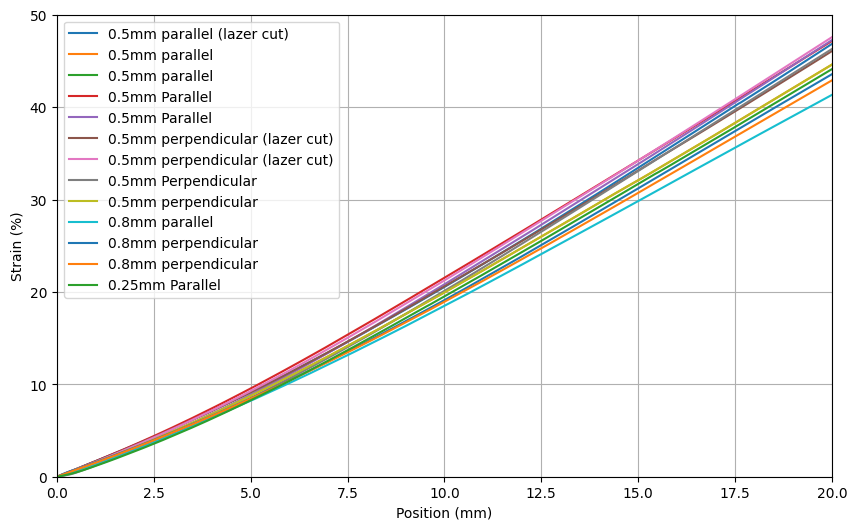

In [237]:
plt.figure(figsize=(10, 6))

plt.plot(df1["Position"][:4901],df1["Strain1"][:4901]*100, markersize=1, label = '0.5mm parallel (lazer cut)')
plt.plot(df4["Position"][:1050], df4["Strain"][:1050]*100, markersize=1, label = '0.5mm parallel')
plt.plot(df5['Position'][:3499],df5["Strain1"][:3499]*100, markersize=1, label = '0.5mm parallel')
plt.plot(df12["Position"][:1770], df12["Strain1"][:1770]*100, markersize=1, label = '0.5mm Parallel')
plt.plot(df13["Position"][:989], df13["Strain1"][:989]*100, markersize=1, label = '0.5mm Parallel')
plt.plot(df2["Position"][:4733],df2["Strain1"][:4733]*100, markersize=1, label = '0.5mm perpendicular (lazer cut)')
plt.plot(df3["Position"][:1402],df3["Strain1"][:1402]*100, markersize=1, label = '0.5mm perpendicular (lazer cut)')
plt.plot(df10["Position"][:994], df10["Strain1"][:994]*100, label = '0.5mm Perpendicular')
plt.plot(df6["Position"][:1051],df6["Strain1"][:1051]*100, markersize=1, label = '0.5mm perpendicular')
plt.plot(df7["Position"][:1710], df7["Strain"][:1710]*100, markersize=1, label = '0.8mm parallel') #Weird ass data
plt.plot(df8["Position"][:581],df8["Strain1"][:581]*100, markersize=1, label = '0.8mm perpendicular')
plt.plot(df9["Position"][:1743], df9["Strain1"][:1743]*100, label = '0.8mm perpendicular')
#plt.plot(df11["Position"][:816], df11["Strain1"][:816]*100, markersize=1, label = '0.5mm Perpendicular')
#plt.plot(df15["Position"][:1280], df15["Strain1"][:1280]*100, markersize=1, label = '0.25mm Parallel') 
#plt.plot(df14["Position"][:1995], df14["Strain2"][:1995]*100, markersize=1, label = '0.25mm Perpendicular') 
#plt.plot(df16["Position"][:8331], df16["Strain1"][:8331]*100, markersize=1, label = '0.25mm Perpendicular') 

plt.xlim(0,20)
plt.ylim(0,50)

plt.ylabel("Strain (%)")
plt.xlabel("Position (mm)")
plt.legend()
plt.grid()

df4 (0.5mm parallel): Young's modulus = 654.29 MPa
df12 (0.5mm parallel): Young's modulus = 700.40 MPa
df13 (0.5mm parallel): Young's modulus = 720.58 MPa
df3 (0.5mm perpendicular, laser cut): Young's modulus = 629.02 MPa
df6 (0.5mm perpendicular): Young's modulus = 654.63 MPa
df10 (0.5mm perpendicular): Young's modulus = 672.77 MPa
df7 (0.8mm parallel): Young's modulus = 704.05 MPa
df8 (0.8mm perpendicular): Young's modulus = 600.99 MPa
df9 (0.8mm perpendicular): Young's modulus = 746.02 MPa


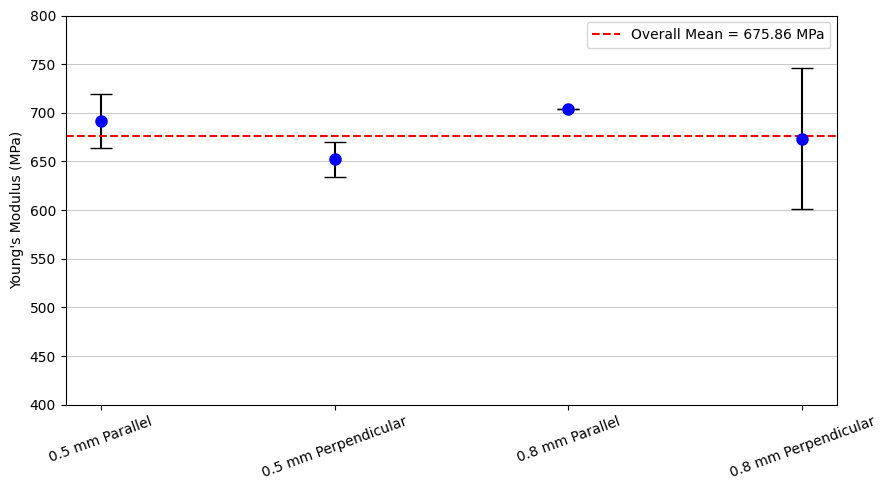

In [316]:
# Raw Young's modulus data for each sample group
data = {
    "0.5 mm Parallel": [get_modulus10(df4["Strain"], df4["Stress"], "df4 (0.5mm parallel)")
, get_modulus10(df12["Strain1"], df12["Stress"], "df12 (0.5mm parallel)")
, get_modulus10(df13["Strain1"], df13["Stress"], "df13 (0.5mm parallel)")
],
    "0.5 mm Perpendicular": [get_modulus20(df3["Strain1"], df3["Stress"], "df3 (0.5mm perpendicular, laser cut)")
, get_modulus10(df6["Strain1"], df6["Stress"], "df6 (0.5mm perpendicular)")
, get_modulus20(df10["Strain1"], df10["Stress"], "df10 (0.5mm perpendicular)")
],
    "0.8 mm Parallel": [get_modulus10(df7["Strain"], df7["Stress"], "df7 (0.8mm parallel)")
],
    "0.8 mm Perpendicular": [get_modulus10(df8["Strain1"], df8["Stress"], "df8 (0.8mm perpendicular)")
, get_modulus10(df9["Strain1"], df9["Stress"], "df9 (0.8mm perpendicular)")]
}

# Calculate means and standard deviations for each group
labels = list(data.keys())
means = [np.mean(data[label]) for label in labels]
stds = [np.std(data[label]) for label in labels]

# Calculate the overall average modulus across all values
all_values = sum(data.values(), [])  # Flatten list of lists
overall_mean = np.mean(all_values)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

# Plot the means with error bars
ax.errorbar(labels, means, yerr=stds, fmt='o', capsize=8,
            markersize=8, color='blue', ecolor='black', linestyle='None')

# Draw horizontal line for overall average
ax.axhline(overall_mean, linestyle='--', color='red', linewidth=1.5,
           label=f'Overall Mean = {overall_mean:.2f} MPa')

# Formatting
ax.set_ylabel("Young's Modulus (MPa)")
ax.grid(axis='y', linestyle='-', linewidth=0.7, alpha=0.7)
ax.legend()
plt.ylim(400,800)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()